# 10 - TWFE benchmark, treated vs. control semivariograms, and a protected-area case study

Three self-contained pieces, all on the 1km panel and sample definitions used in notebook 08:

1. **TWFE OLS with `pyfixest`** (cell and year fixed effects) so the results can be set next to the staggered Callaway-Sant'Anna ATTs from notebook 12 (R did). Four models: {no buffer, 35km buffer} x {only newly added PAs, all PA cells}.
2. **Semivariograms** estimated separately on treated cells only and on control cells only.
3. **Case study** of one protected area: forest loss before/after designation against a covariate-matched control pool, for the narrative.

**Caveat on part 1.** Static TWFE with staggered adoption is a weighted average of 2x2 comparisons that can include already-treated cells as controls ("forbidden comparisons"), so it need not equal the C&S ATT even with an identical sample. That gap is itself informative, so these models are a benchmark rather than a replacement for notebook 08.

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'notebooks').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.estimation_workflow_utils import (
    append_tag_to_filename,
    empirical_variogram,
    fit_spherical_variogram,
    treatment_group_for_did,
)

DATA_DIR = PROJECT_ROOT / 'data'
INTERMEDIATE_DIR = DATA_DIR / 'intermediate'
SPATIAL_DIR = INTERMEDIATE_DIR / 'spatial_structure'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIG_DIR = OUTPUT_DIR / 'figures'
for path in [TABLE_DIR, FIG_DIR]:
    path.mkdir(parents=True, exist_ok=True)
print('Project root:', PROJECT_ROOT)

Project root: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2


## User configuration

In [2]:
RUN_TAG = '1km'
START_YEAR = 2001
CELL_COL = 'cell_id'
YEAR_COL = 'year'
OUTCOME_COL = 'loss_m2'
MAIN_BUFFER_KM = 35          # same as notebook 08
BLOCK_KM = 35                # spatial-cluster block size for the alternative SE (= HAC cutoff in nb08)

PANEL_PATH = INTERMEDIATE_DIR / f'panel_treatment_{RUN_TAG}.parquet'
EXPOSURE_PATH = INTERMEDIATE_DIR / append_tag_to_filename('06_nearest_treated_exposure.parquet', RUN_TAG)
CENTROID_PATH = SPATIAL_DIR / append_tag_to_filename('03_grid_centroids.parquet', RUN_TAG)
CORE_COVARIATE_PATH = INTERMEDIATE_DIR / append_tag_to_filename('panel_core_covariates.parquet', RUN_TAG)
WDPA_PATH = INTERMEDIATE_DIR / 'wdpa_colombia_yearly_snapshots.parquet'
CS_OVERALL_PATH = TABLE_DIR / append_tag_to_filename('12_cs_overall_att_by_control_group.csv', RUN_TAG)   # notebook 12 (R did, exact spatial HAC)
COLOMBIA_BOUNDARY_PATH = DATA_DIR / 'raw' / 'boundaries' / 'departamentos' / 'Departamentos_Diciembre_2025_shp'

# Part 2 -- semivariograms
VARIOGRAM_MAX_LAG_KM = 100
VARIOGRAM_BINS = 25
VARIOGRAM_MAX_POINTS = 25_000     # random subsample per group (pair counts grow quadratically)
VARIOGRAM_MAX_PAIRS = 80_000_000
RESID_LATE_YEARS = 5             # residual variogram uses each cell's mean residual over the last N years

# Part 3 -- case study: the 2018 expansion of Serrania de Chiribiquete National Park (Andes-Amazon transition).
# Treated cells and their dates come from notebook 11's re-dated lookup (definition C): cells added to the park
# by the expansion, dated by its legal year (MADS Resolution 1256, July 2018) instead of the Sept 2020 WDPA
# snapshot that first shows it.
CASE_STUDY_LOOKUP_PATH = INTERMEDIATE_DIR / f'cell_treatment_lookup_statusyr_{RUN_TAG}.parquet'
CASE_STUDY_SITE_ID = 19984        # WDPA site id of Serrania de Chiribiquete NNP
CASE_STUDY_COHORT_YEAR = 2018     # legal year of the expansion
CASE_STUDY_DISPLAY_NAME = 'Serranía de Chiribiquete NP (2018 expansion)'
EVENT_WINDOW = (-10, 7)           # event-study window, years relative to the cohort year (2008-2025)           # event-study window, years relative to the cohort year
MATCHES_PER_TREATED = 3           # nearest-neighbour controls per treated cell (with replacement)
CONTROL_MAX_DISTANCE_KM = None    # e.g. 300 to force the control pool to be regional; None = national pool

## Load panel and build the cell-level table

Same inputs as notebook 08. The cell table holds first-treatment year, whether the cell was already protected at the panel start, the never-treated flag, and the minimum distance to the nearest treated cell over the whole panel for never-treated cells. That distance is what defines "clean" controls under a buffer, exactly as in `build_stable_buffered_did_panel`.

In [3]:
import pyarrow.parquet as pq

wanted = [CELL_COL, YEAR_COL, OUTCOME_COL, 'first_treat_year', 'treated_before_panel_start', 'never_treated', 'ever_treated']
wanted = [c for c in wanted if c in pq.ParquetFile(PANEL_PATH).schema_arrow.names]
panel = pd.read_parquet(PANEL_PATH, columns=wanted)
panel[YEAR_COL] = pd.to_numeric(panel[YEAR_COL], errors='coerce').astype('int16')
panel = panel[panel[YEAR_COL] >= START_YEAR].reset_index(drop=True)
panel[OUTCOME_COL] = panel[OUTCOME_COL].astype('float32')
panel['cell_int'], cell_uniques = pd.factorize(panel[CELL_COL])
panel['cell_int'] = panel['cell_int'].astype('int32')

cells = (
    panel.drop_duplicates('cell_int').sort_values('cell_int')
    [['cell_int', CELL_COL, 'first_treat_year', 'treated_before_panel_start', 'never_treated']]
    .reset_index(drop=True)
)
cells['ftd'] = treatment_group_for_did(cells['first_treat_year']).astype(int)
cells['pre_panel'] = cells['treated_before_panel_start'].fillna(False).astype(bool)
cells['never'] = cells['never_treated'].fillna(False).astype(bool)
panel = panel.drop(columns=['first_treat_year', 'treated_before_panel_start', 'never_treated', 'ever_treated', CELL_COL])

# minimum distance to the nearest treated cell, never-treated cells only
exposure = pd.read_parquet(EXPOSURE_PATH, columns=[CELL_COL, YEAR_COL, 'nearest_treated_distance_km'])
exposure = exposure[pd.to_numeric(exposure[YEAR_COL], errors='coerce') >= START_YEAR]
min_dist = exposure.groupby(CELL_COL)['nearest_treated_distance_km'].min()
del exposure
cells['min_dist_km'] = cells[CELL_COL].map(min_dist)
cells.loc[~cells['never'], 'min_dist_km'] = np.nan

centroids = pd.read_parquet(CENTROID_PATH, columns=[CELL_COL, 'centroid_x_m', 'centroid_y_m', 'centroid_lon', 'centroid_lat'])
cells = cells.merge(centroids, on=CELL_COL, how='left')
block_m = BLOCK_KM * 1000.0
bx = np.floor(cells['centroid_x_m'] / block_m).fillna(-1).astype('int64')
by = np.floor(cells['centroid_y_m'] / block_m).fillna(-1).astype('int64')
cells['block'] = pd.factorize(bx * 100_000 + by)[0].astype('int32')

cells['new_treated'] = (cells['ftd'] > START_YEAR) & ~cells['pre_panel']
cells['pre_treated'] = cells['pre_panel'] & (cells['ftd'] > 0)
cells['clean_control'] = cells['never'] & (cells['min_dist_km'] > MAIN_BUFFER_KM)
print(f'Panel rows: {len(panel):,} | cells: {len(cells):,}')
print(cells[['new_treated', 'pre_treated', 'never', 'clean_control']].sum().to_string())

Panel rows: 29,000,450 | cells: 1,160,018
new_treated      103335
pre_treated      122923
never            933675
clean_control    264952


## Part 1 - TWFE OLS with pyfixest

$$\text{loss}_{it} = \beta\, D_{it} + \alpha_i + \gamma_t + \varepsilon_{it}, \qquad D_{it}=\mathbf 1[t \ge g_i]$$

The four models cross two choices:

| | **Only newly added PAs** | **All PA cells** |
|---|---|---|
| treated | cells first protected inside the panel window (`ftd > 2001`, not protected at panel start); this is the notebook-08 treated set | the same cells **plus** cells already protected when the panel starts (D = 1 in every year) |
| **No buffer** | controls = every never-treated cell | same |
| **35km buffer** | controls = never-treated cells always more than 35km from any treated cell | same |

Cells already protected from 2001 have no within-cell variation in D, so they cannot identify beta directly. In TWFE they act as always-treated cells that help pin down the year effects. Their inclusion in the "all PA cells" models is therefore a check on how much that matters.

Standard errors: clustered by cell (default) and by 35km spatial blocks (a coarse stand-in for spatial dependence; the notebook-08 numbers use a Conley-style HAC with a 35km cutoff).

In [4]:
MODEL_SPECS = [
    {'key': 'new_nobuffer',  'treatment': 'Newly added PAs only', 'buffer_km': None,           'include_pre': False},
    {'key': 'new_buffer',    'treatment': 'Newly added PAs only', 'buffer_km': MAIN_BUFFER_KM, 'include_pre': False},
    {'key': 'all_nobuffer',  'treatment': 'All PA cells',         'buffer_km': None,           'include_pre': True},
    {'key': 'all_buffer',    'treatment': 'All PA cells',         'buffer_km': MAIN_BUFFER_KM, 'include_pre': True},
]

def sample_cell_mask(buffer_km, include_pre):
    ctrl = cells['never'] if buffer_km is None else (cells['never'] & (cells['min_dist_km'] > buffer_km))
    keep = cells['new_treated'] | ctrl
    if include_pre:
        keep = keep | cells['pre_treated']
    return keep.to_numpy(), ctrl.to_numpy()

ftd_by_cell = cells['ftd'].to_numpy()
fits, rows = {}, []
resid_cell_means = None

for spec in MODEL_SPECS:
    keep_cell, ctrl_cell = sample_cell_mask(spec['buffer_km'], spec['include_pre'])
    sel = keep_cell[panel['cell_int'].to_numpy()]
    df = panel.loc[sel, ['cell_int', YEAR_COL, OUTCOME_COL]].copy()
    g = ftd_by_cell[df['cell_int'].to_numpy()]
    df['D'] = ((g > 0) & (df[YEAR_COL].to_numpy() >= g)).astype('int8')
    df['block'] = cells['block'].to_numpy()[df['cell_int'].to_numpy()]
    df[YEAR_COL] = df[YEAR_COL].astype('int32')

    fit = pf.feols(f'{OUTCOME_COL} ~ D | cell_int + {YEAR_COL}', data=df, vcov={'CRV1': 'cell_int'})
    b, se_cell, p_cell = float(fit.coef()['D']), float(fit.se()['D']), float(fit.pvalue()['D'])
    if spec['key'] == 'new_buffer':
        r = np.asarray(fit.resid())
        if len(r) == len(df):
            late = df[YEAR_COL].to_numpy() >= int(df[YEAR_COL].max()) - RESID_LATE_YEARS + 1
            resid_cell_means = pd.Series(r[late]).groupby(df['cell_int'].to_numpy()[late]).mean()
    fit.vcov({'CRV1': 'block'})
    se_block, p_block = float(fit.se()['D']), float(fit.pvalue()['D'])
    fit.vcov({'CRV1': 'cell_int'})   # restore for etable
    fits[spec['key']] = fit

    ctrl_mean = float(df.loc[ctrl_cell[df['cell_int'].to_numpy()], OUTCOME_COL].mean())
    rows.append({
        'model': spec['key'], 'treatment': spec['treatment'],
        'buffer_km': 0 if spec['buffer_km'] is None else spec['buffer_km'],
        'coef': b, 'se_cell': se_cell, 'p_cell': p_cell, 'se_block35km': se_block, 'p_block35km': p_block,
        'pct_of_control_mean': 100 * b / ctrl_mean if ctrl_mean else np.nan,
        'n_obs': int(len(df)), 'n_cells': int(df['cell_int'].nunique()),
        'n_treated_cells': int(df.loc[df['D'] == 1, 'cell_int'].nunique()),
        'n_control_cells': int(ctrl_cell[keep_cell].sum()),
    })
    print(f"{spec['key']:<13} beta={b:>9.1f}  se(cell)={se_cell:>7.1f}  se(block)={se_block:>7.1f}  N={len(df):,}")
    del df

twfe_results = pd.DataFrame(rows)

new_nobuffer  beta=   -353.3  se(cell)=   17.2  se(block)=  108.5  N=25,925,250


new_buffer    beta=   -389.1  se(cell)=   18.8  se(block)=  153.5  N=9,207,175


all_nobuffer  beta=   -357.1  se(cell)=   17.1  se(block)=  105.9  N=28,998,325


all_buffer    beta=   -388.5  se(cell)=   17.9  se(block)=  133.9  N=12,280,250


### Results table, side by side with the notebook-12 Callaway-Sant'Anna ATTs (R did)

In [5]:
def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else '.' if p < 0.1 else ''

out = twfe_results.copy()
out['sig_cell'] = out['p_cell'].map(stars)
out['sig_block'] = out['p_block35km'].map(stars)
out['estimator'] = 'TWFE OLS (pyfixest)'

ref_rows = []
if CS_OVERALL_PATH.exists():
    cs12 = pd.read_csv(CS_OVERALL_PATH)
    cs12 = cs12[cs12['control_group'] == 'buffer_35']
    for r in cs12.itertuples(index=False):
        ref_rows.append({
            'model': f'nb12 CS: {r.spec}', 'treatment': 'Newly added PAs only', 'buffer_km': MAIN_BUFFER_KM,
            'coef': r.att, 'se_cell': np.nan, 'se_block35km': r.se_hac,
            'sig_block': r.sig if isinstance(r.sig, str) else '',
            'n_cells': np.nan, 'estimator': "Callaway-Sant'Anna (R did, exact spatial-HAC SE)",
        })
else:
    print('notebook 12 overall-ATT table not found, skipping reference rows:', CS_OVERALL_PATH)
comparison = pd.concat([out, pd.DataFrame(ref_rows)], ignore_index=True)
show_cols = ['estimator', 'model', 'treatment', 'buffer_km', 'coef', 'se_cell', 'se_block35km', 'sig_block', 'pct_of_control_mean', 'n_treated_cells', 'n_control_cells']
display(comparison[show_cols].round(2))
twfe_path = TABLE_DIR / append_tag_to_filename('10_twfe_vs_cs_comparison.csv', RUN_TAG)
comparison.to_csv(twfe_path, index=False)
print('Saved:', twfe_path)

try:
    display(pf.etable(list(fits.values()), labels={'D': 'Protected (D)'}, model_heads=[s['key'] for s in MODEL_SPECS], type='df'))
except Exception as exc:
    print('etable skipped:', exc)

,estimator,model,treatment,buffer_km,coef,se_cell,se_block35km,sig_block,pct_of_control_mean,n_treated_cells,n_control_cells
0,TWFE OLS (pyfixest),new_nobuffer,Newly added PAs only,0,-353.32,17.23,108.48,**,-21.01,103335.0,933675.0
1,TWFE OLS (pyfixest),new_buffer,Newly added PAs only,35,-389.09,18.76,153.54,*,-29.78,103335.0,264952.0
2,TWFE OLS (pyfixest),all_nobuffer,All PA cells,0,-357.10,17.08,105.87,***,-21.23,226258.0,933675.0
3,TWFE OLS (pyfixest),all_buffer,All PA cells,35,-388.53,17.93,133.86,**,-29.74,226258.0,264952.0
4,"Callaway-Sant'Anna (R did, exact spatial-HAC SE)",nb12 CS: baseline,Newly added PAs only,35,-103.65,NaN,124.22,,NaN,NaN,NaN
5,"Callaway-Sant'Anna (R did, exact spatial-HAC SE)",nb12 CS: anticipation1,Newly added PAs only,35,-337.01,NaN,180.10,.,NaN,NaN,NaN
6,"Callaway-Sant'Anna (R did, exact spatial-HAC SE)",nb12 CS: dr_geography,Newly added PAs only,35,-125.24,NaN,270.52,,NaN,NaN,NaN
7,"Callaway-Sant'Anna (R did, exact spatial-HAC SE)",nb12 CS: dr_geography_anticipation1,Newly added PAs only,35,-54.72,NaN,373.94,,NaN,NaN,NaN


Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\outputs\tables\10_twfe_vs_cs_comparison_1km.csv


loss_m2                           \
                                new_nobuffer               new_buffer   
                                         (1)                      (2)   
coef  Protected (D)  -353.320*** \n (17.232)  -389.087*** \n (18.762)   
fe    cell_int                             -                        -   
      year                                 -                        -   
stats Observations                25,925,250                9,207,175   
      R²                                0.13                    0.138   

                                                                       
                                all_nobuffer               all_buffer  
                                         (3)                      (4)  
coef  Protected (D)  -357.102*** \n (17.079)  -388.535*** \n (17.929)  
fe    cell_int                             -                        -  
      year                                 -                        -  
stats Observations                28,998,325               12,280,250  
      R²                               0.131                    0.136

**Reading the table.** `coef` is the average change in annual forest loss (m2 per 1km2 cell-year) associated with a cell becoming protected. Compare `new_buffer` with nb12 `baseline` first: same sample, different estimator. Then compare across buffers (the gap between `*_nobuffer` and `*_buffer` is the contamination of the control group by spillovers or leakage) and across treatment definitions (whether including cells that were already protected changes anything).

## Part 2 - Semivariograms: treated units only vs. control units only

$$\hat\gamma(h)=\frac{1}{2|N(h)|}\sum_{(i,j)\in N(h)}\big(z_i-z_j\big)^2$$

Computed within each group, so every pair has both cells in the same group (treated-treated or control-control). Two cell-level variables:

* **Pre-treatment mean forest loss** (`forest_loss_pre_mean_m2`, from the core covariates): descriptive spatial dependence in the outcome level. Raw outcome levels share ecology, climate and regional policy, so they will show long-range dependence almost everywhere.
* **Mean TWFE residual over the last 5 panel years** from the 35km-buffer, newly-added-PA model: spatial dependence in what the model leaves unexplained, which is the part that matters for standard errors. (The all-years cell mean cannot be used: with cell fixed effects it is zero by construction.)

Each group is randomly subsampled to `VARIOGRAM_MAX_POINTS` cells because the pair count is quadratic. A spherical model gives the nugget, sill and practical range; the 35km line marks the HAC cutoff used in notebook 08.

In [6]:
core = pd.read_parquet(CORE_COVARIATE_PATH, columns=[CELL_COL, 'forest_loss_pre_mean_m2', 'base_m2', 'elevation_m_mean', 'slope_deg_mean', 'ruggedness_m_mean'])
vg_cells = cells.merge(core[[CELL_COL, 'forest_loss_pre_mean_m2']], on=CELL_COL, how='left')
if resid_cell_means is not None:
    vg_cells['twfe_resid_mean'] = vg_cells['cell_int'].map(resid_cell_means)
else:
    vg_cells['twfe_resid_mean'] = np.nan

groups = {
    'Treated cells (newly added PAs)': vg_cells['new_treated'],
    f'Control cells (never treated, >{MAIN_BUFFER_KM}km)': vg_cells['clean_control'],
}
variables = {
    'forest_loss_pre_mean_m2': 'Pre-treatment mean forest loss (m2)',
    'twfe_resid_mean': 'Mean TWFE residual, last 5 years (m2)',
}

vg_rows, vg_fits, vg_curves = [], {}, {}
for var, var_label in variables.items():
    for gname, gmask in groups.items():
        sub = vg_cells.loc[gmask, ['centroid_x_m', 'centroid_y_m', var]].dropna()
        if len(sub) < 50:
            print(f'Skipping {var} / {gname}: only {len(sub)} usable cells')
            continue
        vg = empirical_variogram(
            sub, value_col=var, max_lag_km=VARIOGRAM_MAX_LAG_KM, n_bins=VARIOGRAM_BINS,
            max_points=VARIOGRAM_MAX_POINTS, max_pairs=VARIOGRAM_MAX_PAIRS, random_state=0,
        )
        vg['variable'], vg['group'] = var, gname
        vg_curves[(var, gname)] = vg
        try:
            fit = fit_spherical_variogram(vg['lag_km'], vg['semivariance'], n_pairs=vg['n_pairs'])
            vg_fits[(var, gname)] = fit
            vg_rows.append({'variable': var, 'group': gname, 'n_cells_used': min(len(sub), VARIOGRAM_MAX_POINTS),
                            'nugget': fit['nugget'], 'sill': fit['sill'], 'range_km': fit['range_km'], 'r2': fit['r_squared']})
        except Exception as exc:
            print(f'Spherical fit failed for {var} / {gname}: {exc}')
        print(f'done: {var} | {gname} | cells={len(sub):,}')

variogram_summary = pd.DataFrame(vg_rows)
display(variogram_summary.round(2))
variogram_summary.to_csv(TABLE_DIR / append_tag_to_filename('10_variogram_treated_vs_control_summary.csv', RUN_TAG), index=False)
pd.concat(vg_curves.values(), ignore_index=True).to_csv(TABLE_DIR / append_tag_to_filename('10_variogram_treated_vs_control_curves.csv', RUN_TAG), index=False)

done: forest_loss_pre_mean_m2 | Treated cells (newly added PAs) | cells=103,335


done: forest_loss_pre_mean_m2 | Control cells (never treated, >35km) | cells=264,952


done: twfe_resid_mean | Treated cells (newly added PAs) | cells=103,335


done: twfe_resid_mean | Control cells (never treated, >35km) | cells=264,952


,variable,group,n_cells_used,nugget,sill,range_km,r2
0,forest_loss_pre_mean_m2,Treated cells (newly added PAs),25000,3473839.36,19481579.70,294.00,0.87
1,forest_loss_pre_mean_m2,"Control cells (never treated, >35km)",25000,11606276.14,6459673.43,98.98,0.82
2,twfe_resid_mean,Treated cells (newly added PAs),25000,6218732.41,15137085.39,234.62,0.92
3,twfe_resid_mean,"Control cells (never treated, >35km)",25000,23431275.43,25966576.28,4.50,-0.06


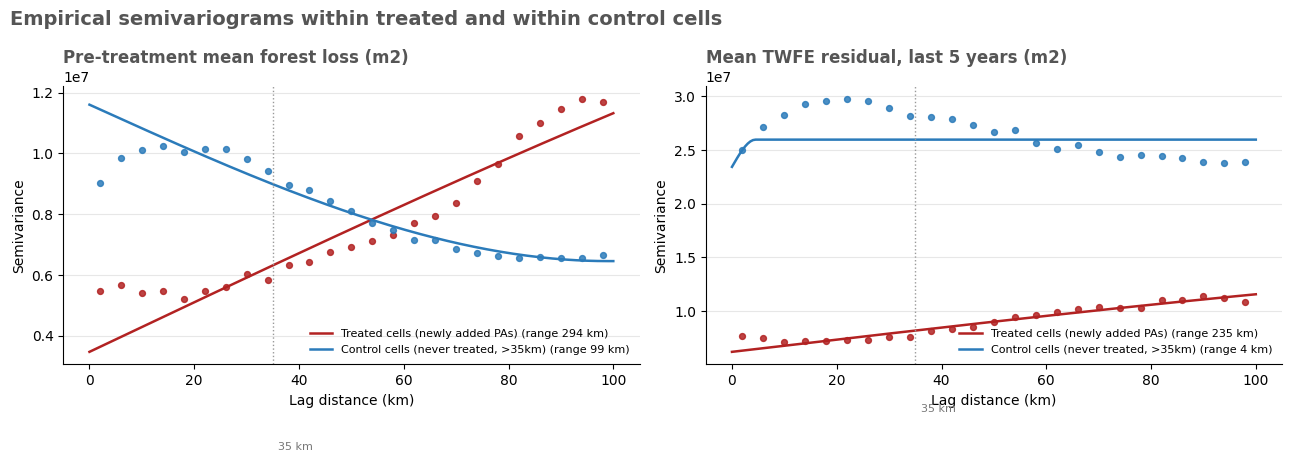

Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\outputs\figures\10_variogram_treated_vs_control_1km.png


In [7]:
colors = ['#b22222', '#2b7bba']
fig, axes = plt.subplots(1, len(variables), figsize=(6.5 * len(variables), 5), squeeze=False)
for ax, (var, var_label) in zip(axes[0], variables.items()):
    for color, gname in zip(colors, groups):
        vg = vg_curves.get((var, gname))
        if vg is None:
            continue
        ax.scatter(vg['lag_km'], vg['semivariance'], s=18, color=color, alpha=0.85, zorder=3)
        fit = vg_fits.get((var, gname))
        if fit is not None:
            xs = np.linspace(0, VARIOGRAM_MAX_LAG_KM, 200)
            ax.plot(xs, fit['predict'](xs), color=color, linewidth=1.8, label=f"{gname} (range {fit['range_km']:.0f} km)")
        else:
            ax.plot([], [], color=color, label=gname)
    ax.axvline(MAIN_BUFFER_KM, color='#999999', linestyle=':', linewidth=1)
    ax.text(MAIN_BUFFER_KM + 1, ax.get_ylim()[1] * 0.02, f'{MAIN_BUFFER_KM} km', color='#777777', fontsize=8)
    ax.set_title(var_label, loc='left', color='#555555', fontsize=12, weight='bold')
    ax.set_xlabel('Lag distance (km)')
    ax.set_ylabel('Semivariance')
    ax.grid(True, axis='y', color='#e7e7e7', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(frameon=False, fontsize=8, loc='lower right')
fig.suptitle('Empirical semivariograms within treated and within control cells', x=0.01, ha='left', color='#555555', fontsize=14, weight='bold')
fig.tight_layout()
vg_fig_path = FIG_DIR / append_tag_to_filename('10_variogram_treated_vs_control.png', RUN_TAG)
fig.savefig(vg_fig_path, dpi=220, bbox_inches='tight')
plt.show()
print('Saved:', vg_fig_path)

## Part 3 - Case study: forest loss around one protected area

**Which PA.** Serranía de Chiribiquete National Natural Park (Andes-Amazon transition). The park was created in 1989 and expanded in July 2018 by MADS Resolution 1256 (+1,486,676 ha). WDPA keeps the 1989 `STATUS_YR` on the enlarged polygon and only shows the new boundary from the Sept 2020 snapshot, so notebook 02 dates the expansion area 2020. This case study uses notebook 11's re-dated lookup (definition C), in which the expansion area is its own cohort with the legal year 2018 and the older park area keeps 1989.

**Treated cells.** Cells that definition C assigns to the Chiribiquete expansion (site 19984, year 2018). Cells of the older park area are pre-2001 protection and are not used. `search_pa('name fragment')` below lists WDPA records by name.

**Control pool.** Never-treated cells that are more than 35km from any treated cell (the notebook-08 clean-control set), matched to each treated cell by nearest neighbour on standardised **time-invariant geography** (elevation, slope, ruggedness, base forest area) and **pre-designation mean loss level**. Pre-designation loss *trends* are deliberately not matched on, so any parallel pre-trend shown is evidence and not an artefact of the matching.

In [8]:
import geopandas as gpd
import shapely
from scipy.spatial import cKDTree

def search_pa(fragment, latest_only=True):
    g = gpd.read_parquet(WDPA_PATH, columns=['NAME', 'WDPAID', 'STATUS_YR', 'DESIG_ENG', 'GIS_AREA', 'wdpa_snapshot_year', 'geometry'])
    m = g[g['NAME'].str.contains(fragment, case=False, na=False)].drop(columns='geometry')
    if latest_only and len(m):
        m = m.sort_values('wdpa_snapshot_year').drop_duplicates('WDPAID', keep='last')
    return m.sort_values('STATUS_YR').reset_index(drop=True)

# Example: search_pa('Lago Azul')

In [9]:
redated = pd.read_parquet(CASE_STUDY_LOOKUP_PATH)
redated['cell_id'] = redated['cell_id'].astype('string')
pa_name = CASE_STUDY_DISPLAY_NAME
cohort_year = CASE_STUDY_COHORT_YEAR
exp_cells = redated.loc[
    (redated['c_site_id'] == CASE_STUDY_SITE_ID)
    & (redated['year_statusyr_expansions'] == cohort_year)
    & redated['c_source'].str.startswith('expansion'),
    'cell_id',
]
treated_mask = cells[CELL_COL].isin(exp_cells).to_numpy()
treated_ids = cells.loc[treated_mask, 'cell_int'].to_numpy()
print(f'PA: {pa_name}; cohort year (legal): {cohort_year}')
print(f'Expansion cells in the re-dated lookup: {len(exp_cells):,}; found in the panel: {len(treated_ids):,}')
print('Their treatment year under the current (nb02) dating:')
print(cells.loc[treated_mask, 'ftd'].value_counts().sort_index().to_string())

PA: Serranía de Chiribiquete NP (2018 expansion); cohort year (legal): 2018
Expansion cells in the re-dated lookup: 15,095; found in the panel: 15,095
Their treatment year under the current (nb02) dating:
ftd
2018    15095


In [10]:
# Pre-designation mean loss per cell, then nearest-neighbour matching
pre_rows = panel[panel[YEAR_COL] < cohort_year]
pre_mean = pre_rows.groupby('cell_int')[OUTCOME_COL].mean().rename('pre_loss_mean')
feat = (
    cells[['cell_int', CELL_COL, 'centroid_x_m', 'centroid_y_m', 'clean_control']]
    .merge(core.drop(columns=['forest_loss_pre_mean_m2']), on=CELL_COL, how='left')
    .merge(pre_mean, left_on='cell_int', right_index=True, how='left')
)
FEATURES = ['elevation_m_mean', 'slope_deg_mean', 'ruggedness_m_mean', 'base_m2', 'pre_loss_mean']
feat = feat.dropna(subset=FEATURES)
is_treated = feat['cell_int'].isin(treated_ids)
pool = feat[feat['clean_control']]
tr = feat[is_treated]

if CONTROL_MAX_DISTANCE_KM is not None:
    cx, cy = tr['centroid_x_m'].mean(), tr['centroid_y_m'].mean()
    d_km = np.hypot(pool['centroid_x_m'] - cx, pool['centroid_y_m'] - cy) / 1000.0
    pool = pool[d_km <= CONTROL_MAX_DISTANCE_KM]

mu, sd = pool[FEATURES].mean(), pool[FEATURES].std().replace(0, 1)
tree = cKDTree(((pool[FEATURES] - mu) / sd).to_numpy())
dist, idx = tree.query(((tr[FEATURES] - mu) / sd).to_numpy(), k=MATCHES_PER_TREATED)
matched_ids = np.unique(pool['cell_int'].to_numpy()[np.asarray(idx).ravel()])
print(f'Treated cells with complete features: {len(tr):,} | control candidates: {len(pool):,} | unique matched controls: {len(matched_ids):,}')

bal = pd.DataFrame({
    'treated': tr[FEATURES].mean(),
    'matched_controls': feat[feat['cell_int'].isin(matched_ids)][FEATURES].mean(),
    'all_clean_controls': feat[feat['clean_control']][FEATURES].mean(),
})
bal['std_diff_matched'] = (bal['treated'] - bal['matched_controls']) / feat[feat['clean_control']][FEATURES].std()
bal['std_diff_all'] = (bal['treated'] - bal['all_clean_controls']) / feat[feat['clean_control']][FEATURES].std()
display(bal.round(3))
bal.to_csv(TABLE_DIR / append_tag_to_filename('10_case_study_balance.csv', RUN_TAG))

Treated cells with complete features: 15,095 | control candidates: 264,952 | unique matched controls: 8,523


,treated,matched_controls,all_clean_controls,std_diff_matched,std_diff_all
elevation_m_mean,250.013,237.410,185.080,0.080,0.414
slope_deg_mean,2.091,2.488,3.693,-0.117,-0.470
ruggedness_m_mean,2.453,2.944,4.448,-0.107,-0.436
base_m2,748965.530,705817.483,633408.591,0.097,0.261
pre_loss_mean,71.473,316.477,1184.360,-0.058,-0.262


In [11]:
all_ctrl_ids = feat.loc[feat['clean_control'], 'cell_int'].to_numpy()
def yearly(ids):
    d = panel.loc[panel['cell_int'].isin(ids), ['cell_int', YEAR_COL, OUTCOME_COL]]
    g = d.groupby(YEAR_COL)[OUTCOME_COL]
    out = pd.DataFrame({'mean': g.mean(), 'sem': g.std() / np.sqrt(g.count()), 'n': g.count()})
    return out

evo = {
    'treated': yearly(tr['cell_int'].to_numpy()),
    'matched': yearly(matched_ids),
    'all_controls': yearly(all_ctrl_ids),
}
evo_long = pd.concat({k: v for k, v in evo.items()}, names=['group', 'year']).reset_index()
evo_long['event_time'] = evo_long['year'] - cohort_year
evo_long.to_csv(TABLE_DIR / append_tag_to_filename('10_case_study_yearly_means.csv', RUN_TAG), index=False)

def pre_post(series, cohort):
    s = series['mean']
    pre, post = s[s.index < cohort], s[s.index >= cohort]
    slope = lambda x: np.polyfit(x.index.to_numpy(float), x.to_numpy(float), 1)[0] if len(x) > 1 else np.nan
    return {'pre_mean': pre.mean(), 'post_mean': post.mean(), 'change': post.mean() - pre.mean(), 'pre_trend_per_yr': slope(pre), 'post_trend_per_yr': slope(post)}

summary = pd.DataFrame({k: pre_post(v, cohort_year) for k, v in evo.items()}).T
summary['pct_change'] = 100 * summary['change'] / summary['pre_mean']
did_matched = summary.loc['treated', 'change'] - summary.loc['matched', 'change']
did_all = summary.loc['treated', 'change'] - summary.loc['all_controls', 'change']
display(summary.round(1))
print(f'Difference-in-means DiD vs matched controls:      {did_matched:,.1f} m2 per cell-year')
print(f'Difference-in-means DiD vs all clean controls:    {did_all:,.1f} m2 per cell-year')
summary.to_csv(TABLE_DIR / append_tag_to_filename('10_case_study_pre_post_summary.csv', RUN_TAG))

,pre_mean,post_mean,change,pre_trend_per_yr,post_trend_per_yr,pct_change
treated,71.5,962.4,891.0,9.9,-94.2,1246.6
matched,316.5,3031.5,2715.1,27.3,-16.3,857.9
all_controls,1184.4,1565.9,381.6,38.7,-136.4,32.2


Difference-in-means DiD vs matched controls:      -1,824.1 m2 per cell-year
Difference-in-means DiD vs all clean controls:    509.4 m2 per cell-year


### Event-study regression for the case study

Two-way fixed-effects event study on the treated cells and the matched controls, with event-time dummies interacted with treatment and the year before designation as the reference:

$$\text{loss}_{it}=\sum_{k\neq -1}\beta_k\,\mathbf 1[t-g=k]\cdot \text{Treated}_i+\alpha_i+\gamma_t+\varepsilon_{it}$$

Pre-designation coefficients near zero are the parallel-trends check; post-designation coefficients are the dynamic effect. Standard errors are clustered by cell (a single PA's cells are spatially adjacent, so read the bands as optimistic).

,event_time,Estimate,se,ci_low,ci_high
0,-10,377.5,156.8,70.1,684.9
1,-9,454.5,153.2,154.2,754.7
2,-8,465.6,153.4,164.8,766.4
3,-7,543.9,153.0,244.1,843.8
4,-6,559.9,152.9,260.2,859.6
5,-5,428.2,154.4,125.6,730.8
6,-4,323.4,153.8,21.9,624.9
7,-3,336.5,158.4,26.1,646.9
8,-2,206.5,141.5,-70.8,483.8
0,-1,0.0,0.0,0.0,0.0


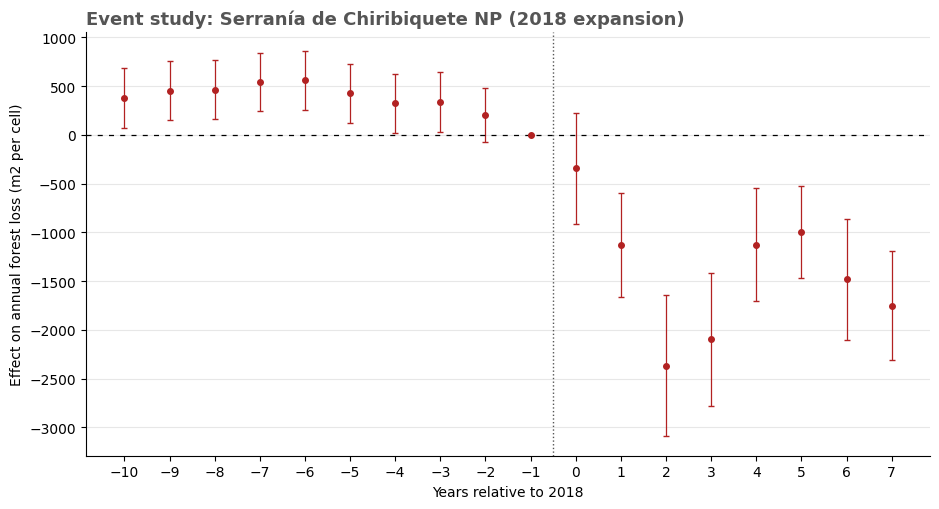

Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\outputs\figures\10_case_study_event_study_1km.png


In [12]:
C_T, C_M, C_A = '#b22222', '#2b7bba', '#9a9a9a'
es_ids = np.concatenate([tr['cell_int'].to_numpy(), matched_ids])
es = panel.loc[panel['cell_int'].isin(es_ids), ['cell_int', YEAR_COL, OUTCOME_COL]].copy()
es['treated'] = es['cell_int'].isin(tr['cell_int']).astype('int8')
es['event_time'] = (es[YEAR_COL].astype('int32') - cohort_year).astype('int32')
es = es[es['event_time'].between(*EVENT_WINDOW)].copy()
es[YEAR_COL] = es[YEAR_COL].astype('int32')

es_fit = pf.feols(f'{OUTCOME_COL} ~ i(event_time, treated, ref=-1) | cell_int + {YEAR_COL}', data=es, vcov={'CRV1': 'cell_int'})
tidy = es_fit.tidy().reset_index()
tidy['event_time'] = tidy['Coefficient'].str.extract(r'event_time::(-?\d+)')[0].astype(int)
ci_lo, ci_hi = tidy.columns[tidy.columns.str.contains('2.5')][0], tidy.columns[tidy.columns.str.contains('97.5')][0]
tidy = pd.concat([tidy[['event_time', 'Estimate', 'Std. Error', ci_lo, ci_hi]].rename(columns={'Std. Error': 'se', ci_lo: 'ci_low', ci_hi: 'ci_high'}),
                  pd.DataFrame({'event_time': [-1], 'Estimate': [0.0], 'se': [0.0], 'ci_low': [0.0], 'ci_high': [0.0]})]).sort_values('event_time')
tidy.to_csv(TABLE_DIR / append_tag_to_filename('10_case_study_event_study.csv', RUN_TAG), index=False)
display(tidy.round(1))

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.errorbar(tidy['event_time'], tidy['Estimate'], yerr=[tidy['Estimate'] - tidy['ci_low'], tidy['ci_high'] - tidy['Estimate']],
            fmt='o', color=C_T, ecolor=C_T, elinewidth=0.9, capsize=2.5, markersize=4)
ax.axhline(0, color='black', linewidth=0.9, linestyle=(0, (4, 5)))
ax.axvline(-0.5, color='#555555', linestyle=':', linewidth=1)
ax.set_xticks(range(EVENT_WINDOW[0], EVENT_WINDOW[1] + 1))
ax.set_xlabel(f'Years relative to {cohort_year}'); ax.set_ylabel('Effect on annual forest loss (m2 per cell)')
ax.set_title(f'Event study: {pa_name}', loc='left', color='#555555', fontsize=13, weight='bold')
ax.grid(True, axis='y', color='#e7e7e7', linewidth=0.8)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout()
es_fig = FIG_DIR / append_tag_to_filename('10_case_study_event_study.png', RUN_TAG)
fig.savefig(es_fig, dpi=220, bbox_inches='tight'); plt.show(); print('Saved:', es_fig)

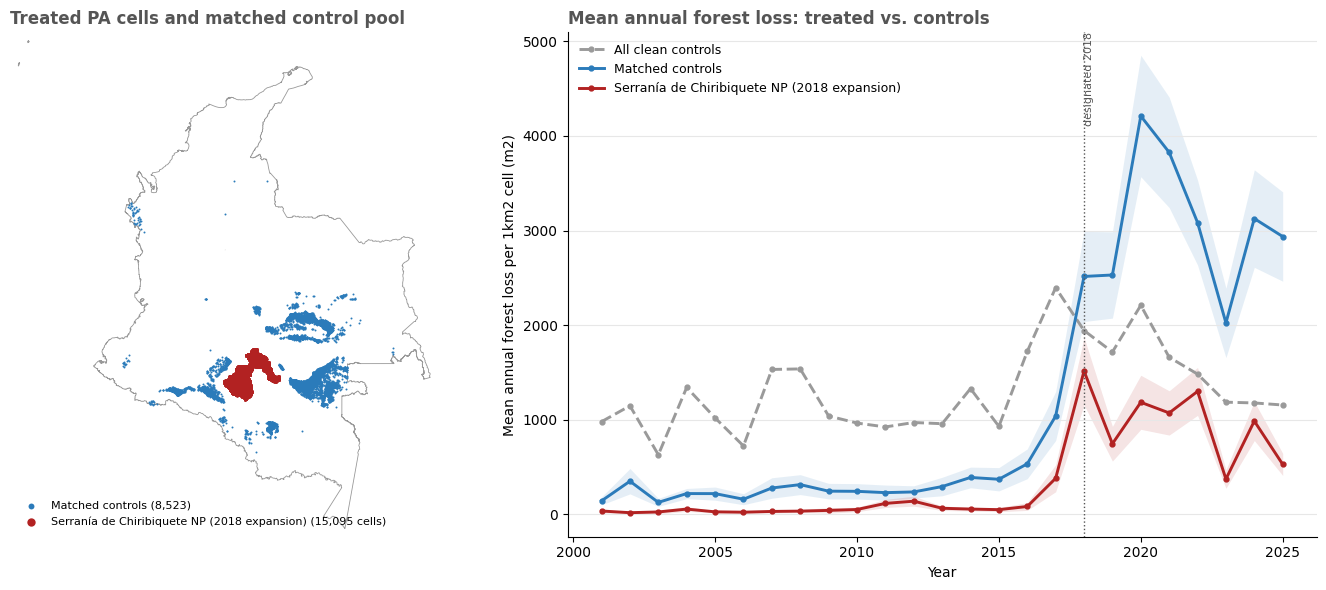

Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\outputs\figures\10_case_study_map_and_levels_1km.png


In [13]:
try:
    outline = gpd.read_file(COLOMBIA_BOUNDARY_PATH).to_crs('EPSG:4326').dissolve().boundary
except Exception as exc:
    outline = None
    print('Colombia outline not loaded:', exc)

C_T, C_M, C_A = '#b22222', '#2b7bba', '#9a9a9a'
fig, (ax_map, ax_raw) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 1.35]})

# --- map ---
if outline is not None:
    outline.plot(ax=ax_map, color='#999999', linewidth=0.6, zorder=1)
    minx, miny, maxx, maxy = outline.total_bounds
    ax_map.set_xlim(minx - 0.3, maxx + 0.3); ax_map.set_ylim(miny - 0.3, maxy + 0.3)
cxy = cells.set_index('cell_int')[['centroid_lon', 'centroid_lat']]
ax_map.scatter(cxy.loc[matched_ids, 'centroid_lon'], cxy.loc[matched_ids, 'centroid_lat'], s=2, color=C_M, linewidths=0, zorder=2, rasterized=True, label=f'Matched controls ({len(matched_ids):,})')
ax_map.scatter(cxy.loc[tr['cell_int'], 'centroid_lon'], cxy.loc[tr['cell_int'], 'centroid_lat'], s=4, color=C_T, linewidths=0, zorder=3, rasterized=True, label=f'{pa_name} ({len(tr):,} cells)')
ax_map.set_aspect('equal'); ax_map.set_xticks([]); ax_map.set_yticks([])
for s in ax_map.spines.values(): s.set_visible(False)
ax_map.set_title('Treated PA cells and matched control pool', loc='left', color='#555555', fontsize=12, weight='bold')
ax_map.legend(loc='lower left', frameon=False, fontsize=8, markerscale=3)

# --- raw levels ---
for key, color, ls, lab in [('all_controls', C_A, '--', 'All clean controls'), ('matched', C_M, '-', 'Matched controls'), ('treated', C_T, '-', f'{pa_name}')]:
    e = evo[key]
    ax_raw.plot(e.index, e['mean'], color=color, linestyle=ls, linewidth=2.1, marker='o', markersize=3.5, label=lab)
    if key != 'all_controls':
        ax_raw.fill_between(e.index, e['mean'] - 1.96 * e['sem'], e['mean'] + 1.96 * e['sem'], color=color, alpha=0.12, linewidth=0)
ax_raw.axvline(cohort_year, color='#555555', linestyle=':', linewidth=1)
ax_raw.text(cohort_year, ax_raw.get_ylim()[1], f'designated {cohort_year}', rotation=90, va='top', ha='left', fontsize=8, color='#555555')
ax_raw.set_xlabel('Year'); ax_raw.set_ylabel('Mean annual forest loss per 1km2 cell (m2)')
ax_raw.set_title('Mean annual forest loss: treated vs. controls', loc='left', color='#555555', fontsize=12, weight='bold')
ax_raw.grid(True, axis='y', color='#e7e7e7', linewidth=0.8)
ax_raw.spines['top'].set_visible(False); ax_raw.spines['right'].set_visible(False)
ax_raw.legend(frameon=False, fontsize=9, loc='upper left')
fig.tight_layout()
cs_fig1 = FIG_DIR / append_tag_to_filename('10_case_study_map_and_levels.png', RUN_TAG)
fig.savefig(cs_fig1, dpi=220, bbox_inches='tight'); plt.show(); print('Saved:', cs_fig1)

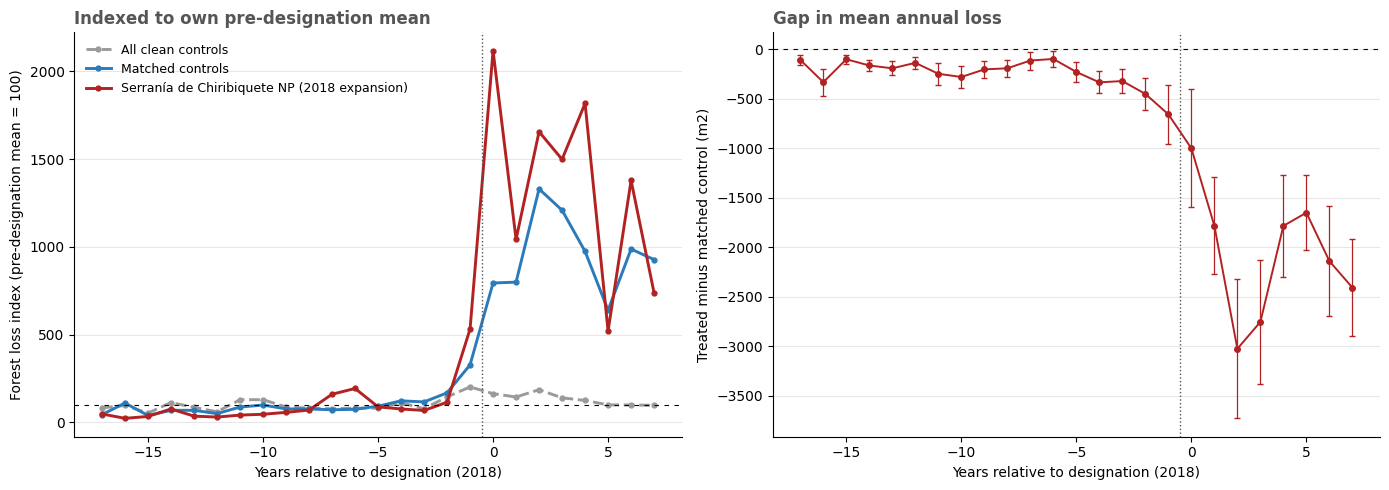

Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\outputs\figures\10_case_study_indexed_and_gap_1km.png


In [14]:
# Second view: indexed to the pre-designation mean (=100) and the treated-minus-control gap in event time
fig, (ax_idx, ax_gap) = plt.subplots(1, 2, figsize=(14, 5))
for key, color, ls, lab in [('all_controls', C_A, '--', 'All clean controls'), ('matched', C_M, '-', 'Matched controls'), ('treated', C_T, '-', f'{pa_name}')]:
    e = evo[key]
    base = e.loc[e.index < cohort_year, 'mean'].mean()
    ax_idx.plot(e.index - cohort_year, 100 * e['mean'] / base, color=color, linestyle=ls, linewidth=2.1, marker='o', markersize=3.5, label=lab)
ax_idx.axhline(100, color='black', linewidth=0.8, linestyle=(0, (4, 5)))
ax_idx.axvline(-0.5, color='#555555', linestyle=':', linewidth=1)
ax_idx.set_xlabel(f'Years relative to designation ({cohort_year})'); ax_idx.set_ylabel('Forest loss index (pre-designation mean = 100)')
ax_idx.set_title('Indexed to own pre-designation mean', loc='left', color='#555555', fontsize=12, weight='bold')
ax_idx.legend(frameon=False, fontsize=9)

gap = (evo['treated']['mean'] - evo['matched']['mean'])
gap_se = np.sqrt(evo['treated']['sem'] ** 2 + evo['matched']['sem'] ** 2)
ax_gap.errorbar(gap.index - cohort_year, gap.values, yerr=1.96 * gap_se.values, fmt='o-', color=C_T, ecolor=C_T, elinewidth=0.9, capsize=2.5, markersize=4, linewidth=1.4)
ax_gap.axhline(0, color='black', linewidth=0.8, linestyle=(0, (4, 5)))
ax_gap.axvline(-0.5, color='#555555', linestyle=':', linewidth=1)
ax_gap.set_xlabel(f'Years relative to designation ({cohort_year})'); ax_gap.set_ylabel('Treated minus matched control (m2)')
ax_gap.set_title('Gap in mean annual loss', loc='left', color='#555555', fontsize=12, weight='bold')
for ax in (ax_idx, ax_gap):
    ax.grid(True, axis='y', color='#e7e7e7', linewidth=0.8)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout()
cs_fig2 = FIG_DIR / append_tag_to_filename('10_case_study_indexed_and_gap.png', RUN_TAG)
fig.savefig(cs_fig2, dpi=220, bbox_inches='tight'); plt.show(); print('Saved:', cs_fig2)

**Narrative use.** Read the figures in this order: (1) the map shows where treated and control cells are; (2) the level plot shows whether the two series moved together before designation and diverged after; (3) the indexed plot removes level differences; (4) the gap plot shows the divergence with a 95% band. Two cautions for the write-up: a single PA is an illustration and not an estimate (the pooled estimate is in notebook 08), and mean loss in a small cell group can be dominated by a few extreme cells or events, so check the cell-level distribution before leaning on any one year.